In [ ]:
!pip install spacy pandas nltk openpyxl matplotlib seaborn

# Download modello italiano spaCy
!python -m spacy download it_core_news_md

# Download stopwords NLTK
import nltk
nltk.download('stopwords')
import re
import pandas as pd
import nltk
import itertools
import spacy
import random
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from nltk.corpus import stopwords

# Caricamento modello spaCy
nlp = spacy.load('it_core_news_md')

# Imposta seed per riproducibilità
random.seed(42)
np.random.seed(42)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 21.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('it_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


#Preprocessing

In [ ]:
def preprocess_without_lemma(text):
    """Preprocessing semplice senza lemmatizzazione"""
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    words = text.split()
    stop_words = set(stopwords.words('italian'))
    return {w for w in words if w not in stop_words}

def preprocess_with_lemma(text):
    """Preprocessing con lemmatizzazione (per SimLex)"""
    doc = nlp(text.lower())
    return {
        token.lemma_ for token in doc
        if not token.is_stop and token.is_alpha
    }

#Caricamento Dati

In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
df = pd.read_excel(list(uploaded.keys())[0])

# Rimuove le ultime due colonne
df = df.iloc[:, :-2]

# Crea dizionario: termine -> lista definizioni
term_dict = {
    row[1]: [x for x in row[2:] if pd.notna(x)]
    for row in df.values
}

STATISTICHE DATASET
Pantalone: 40 definizioni
Microscopio: 39 definizioni
Pericolo: 38 definizioni
Euristica: 36 definizioni



#Sovrapposizione coppie casuali

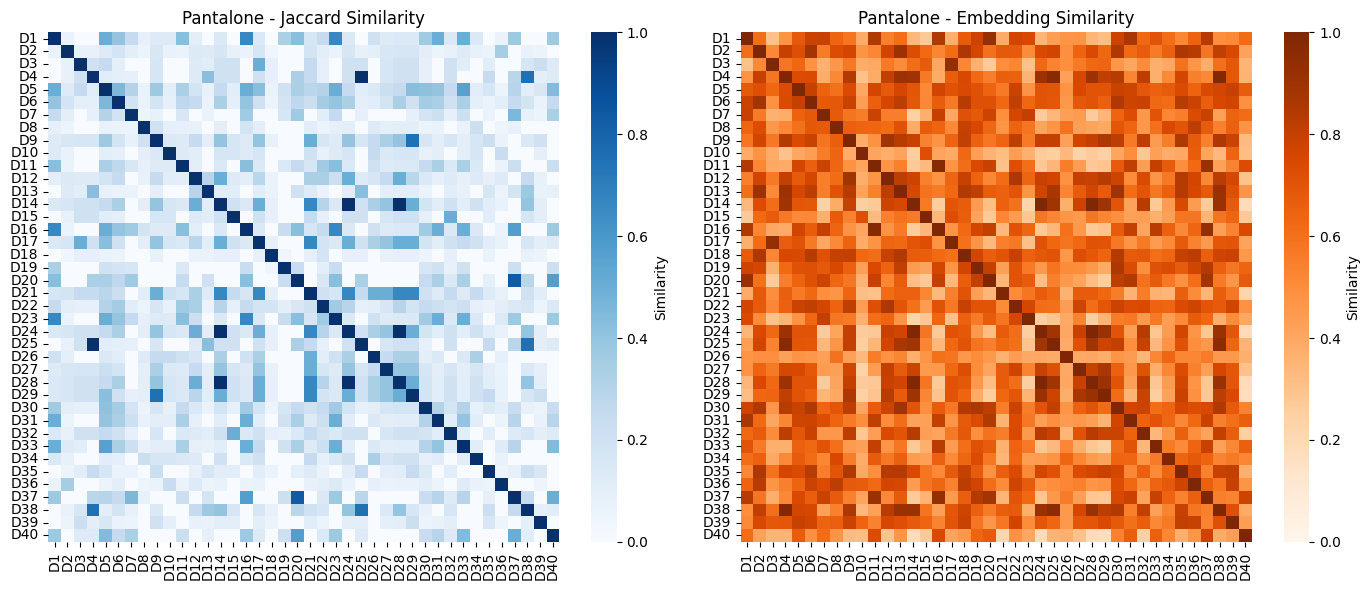


Pantalone:
  Jaccard medio: 0.158
  Embedding medio: 0.598


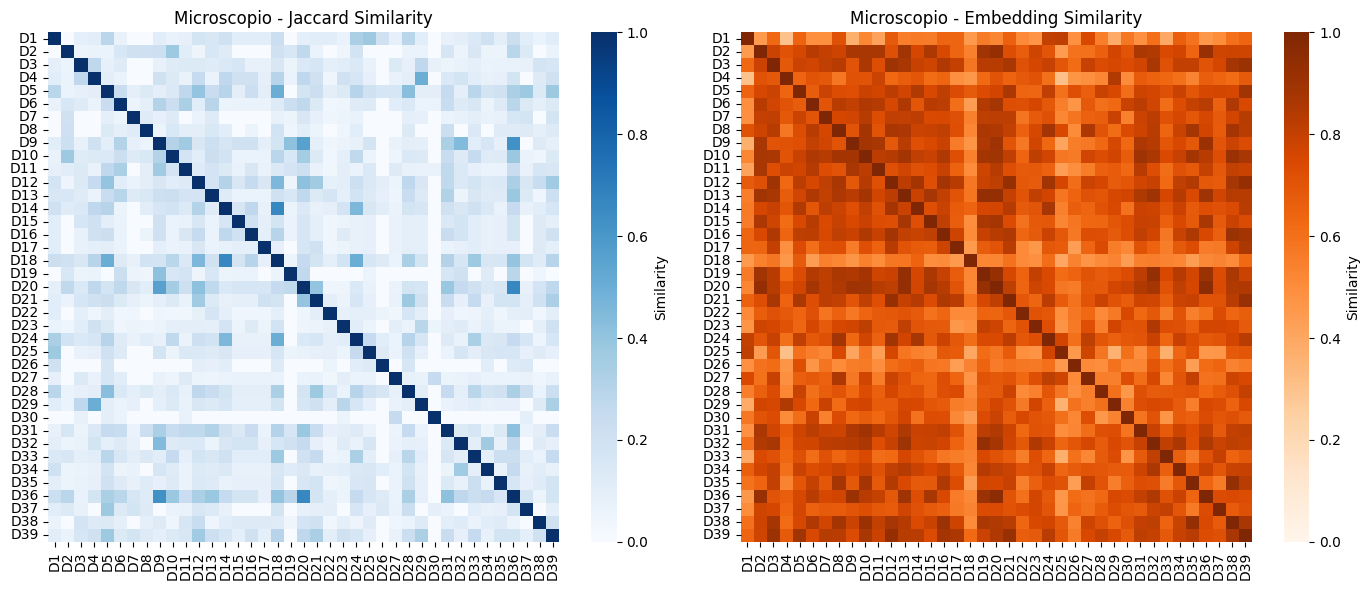


Microscopio:
  Jaccard medio: 0.127
  Embedding medio: 0.706


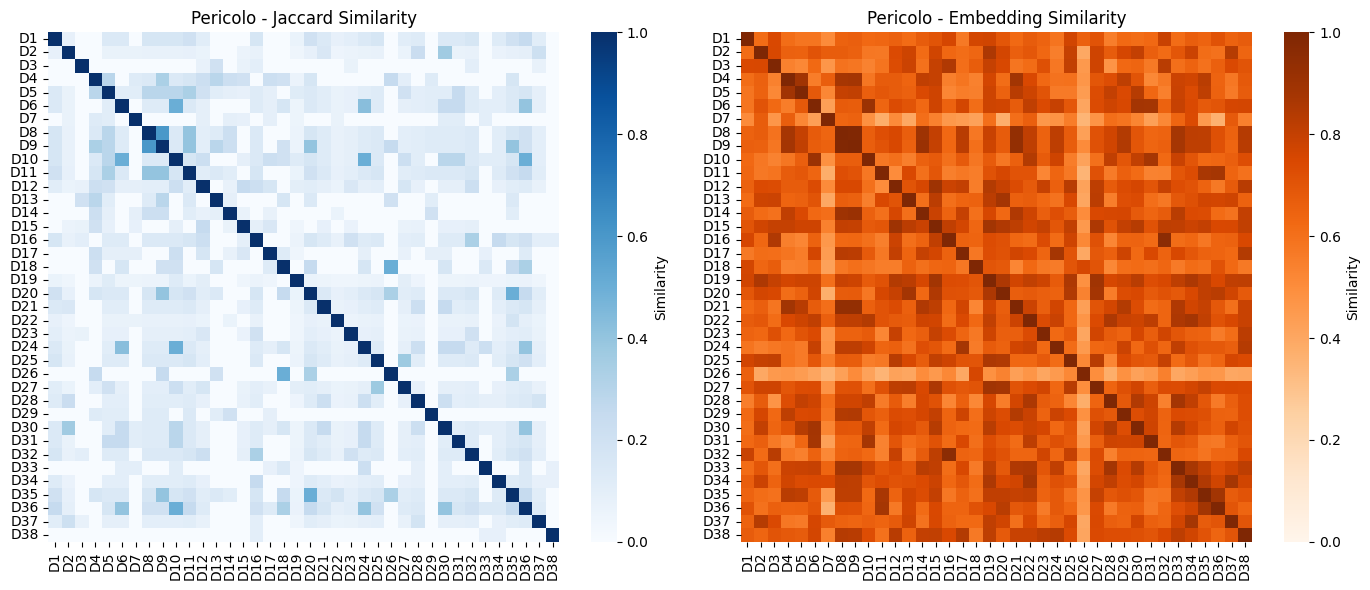


Pericolo:
  Jaccard medio: 0.087
  Embedding medio: 0.685


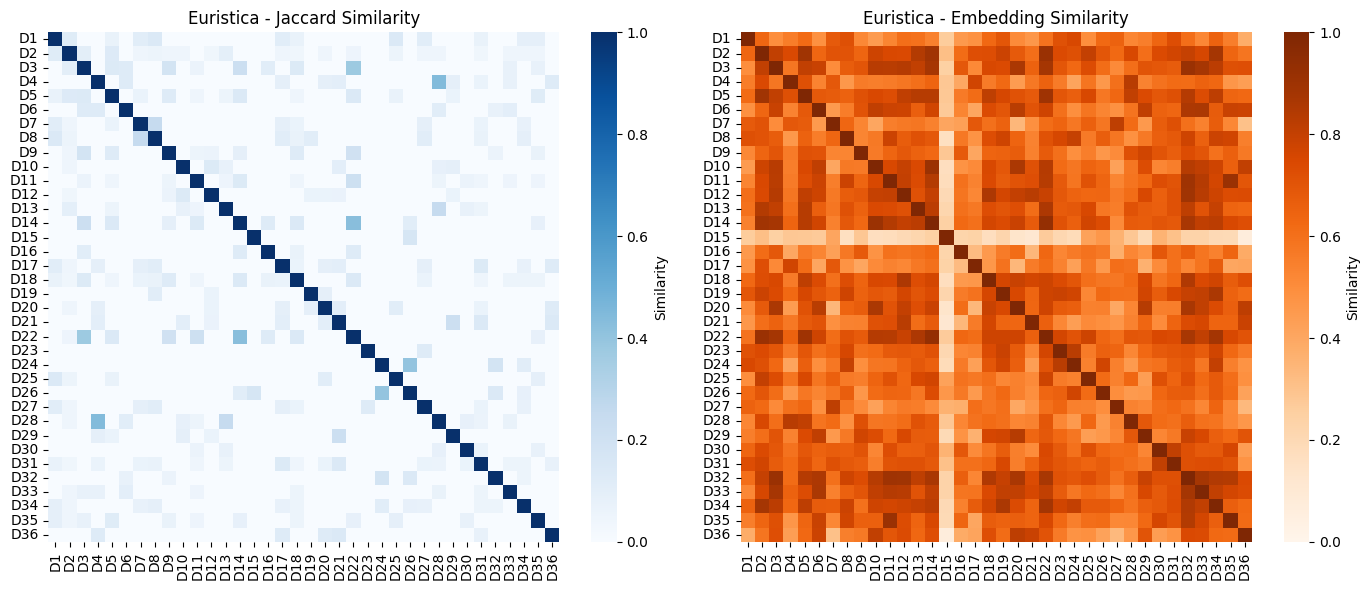


Euristica:
  Jaccard medio: 0.024
  Embedding medio: 0.633


In [ ]:
import seaborn as sns

for term, definitions in term_dict.items():
    n = len(definitions)

    # Matrice per Jaccard
    jaccard_matrix = np.zeros((n, n))
    # Matrice per Embedding
    embedding_matrix = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            if i == j:
                jaccard_matrix[i][j] = 1.0
                embedding_matrix[i][j] = 1.0
            elif i < j:
                # Jaccard
                set1 = preprocess_without_lemma(definitions[i])
                set2 = preprocess_without_lemma(definitions[j])
                jacc = len(set1 & set2) / len(set1 | set2) if len(set1 | set2) > 0 else 0
                jaccard_matrix[i][j] = jaccard_matrix[j][i] = jacc

                # Embedding
                doc1 = nlp(definitions[i])
                doc2 = nlp(definitions[j])
                emb = doc1.similarity(doc2)
                embedding_matrix[i][j] = embedding_matrix[j][i] = emb


    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))


    sns.heatmap(jaccard_matrix,
                annot=show_numbers,  # Numeri solo se poche def
                fmt='.2f' if show_numbers else '',
                cmap='Blues',
                xticklabels=[f'D{i+1}' for i in range(n)],
                yticklabels=[f'D{i+1}' for i in range(n)],
                ax=ax1, vmin=0, vmax=1,
                cbar_kws={'label': 'Similarity'})
    ax1.set_title(f'{term} - Jaccard Similarity')

    sns.heatmap(embedding_matrix,
                annot=show_numbers,  # Numeri solo se poche def
                fmt='.2f' if show_numbers else '',
                cmap='Oranges',
                xticklabels=[f'D{i+1}' for i in range(n)],
                yticklabels=[f'D{i+1}' for i in range(n)],
                ax=ax2, vmin=0, vmax=1,
                cbar_kws={'label': 'Similarity'})
    ax2.set_title(f'{term} - Embedding Similarity')

    plt.tight_layout()
    plt.savefig(f'heatmap_{term}.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Stampa statistiche
    print(f"\n{term}:")
    print(f"  Jaccard medio: {np.mean(jaccard_matrix[np.triu_indices_from(jaccard_matrix, k=1)]):.3f}")
    print(f"  Embedding medio: {np.mean(embedding_matrix[np.triu_indices_from(embedding_matrix, k=1)]):.3f}")

#Definizione categorie

In [ ]:
categories = {
    'concretezza': {
        'concreti': ['Pantalone', 'Microscopio'],
        'astratti': ['Pericolo', 'Euristica']
    },
    'specificità': {
        'generici': ['Pantalone', 'Pericolo'],
        'specifici': ['Microscopio', 'Euristica']
    }
}

print("\n Categorie definite:")
print(f"  Concreti: {categories['concretezza']['concreti']}")
print(f"  Astratti: {categories['concretezza']['astratti']}")
print(f"  Generici: {categories['specificità']['generici']}")
print(f"  Specifici: {categories['specificità']['specifici']}")


📋 Categorie definite:
  Concreti: ['Pantalone', 'Microscopio']
  Astratti: ['Pericolo', 'Euristica']
  Generici: ['Pantalone', 'Pericolo']
  Specifici: ['Microscopio', 'Euristica']


#Similarità lessicale per termine

In [ ]:
simlex_by_term = {}

for term, definitions in term_dict.items():
    simlex_scores = []

    for d1, d2 in itertools.combinations(definitions, 2):
        set1 = preprocess_with_lemma(d1)
        set2 = preprocess_with_lemma(d2)

        common = len(set1 & set2)
        total = len(set1 | set2)
        simlex = common / total if total > 0 else 0

        simlex_scores.append(simlex)

    avg_simlex = sum(simlex_scores) / len(simlex_scores) if simlex_scores else 0
    simlex_by_term[term] = avg_simlex
    print(f"{term:15s} → SimLex medio: {avg_simlex:.3f} (su {len(simlex_scores)} coppie)")

Pantalone       → SimLex medio: 0.171 (su 780 coppie)
Microscopio     → SimLex medio: 0.151 (su 741 coppie)
Pericolo        → SimLex medio: 0.115 (su 703 coppie)
Euristica       → SimLex medio: 0.033 (su 630 coppie)


#Similarità semantica per termine

In [ ]:
simsem_by_term = {}

for term, definitions in term_dict.items():
    simsem_scores = []

    for d1, d2 in itertools.combinations(definitions, 2):
        doc1 = nlp(d1)
        doc2 = nlp(d2)
        simsem = doc1.similarity(doc2)
        simsem_scores.append(simsem)

    avg_simsem = sum(simsem_scores) / len(simsem_scores) if simsem_scores else 0
    simsem_by_term[term] = avg_simsem
    print(f"{term:15s} → SimSem medio: {avg_simsem:.3f} (su {len(simsem_scores)} coppie)")

Pantalone       → SimSem medio: 0.598 (su 780 coppie)
Microscopio     → SimSem medio: 0.706 (su 741 coppie)
Pericolo        → SimSem medio: 0.685 (su 703 coppie)
Euristica       → SimSem medio: 0.633 (su 630 coppie)


#Funzioni di aggregazione

In [ ]:
def calc_avg_simlex(definitions):
    """Calcola SimLex medio tra tutte le coppie di definizioni (Jaccard su lemmi)"""
    scores = []
    for d1, d2 in itertools.combinations(definitions, 2):
        set1 = preprocess_with_lemma(d1)
        set2 = preprocess_with_lemma(d2)
        score = len(set1 & set2) / len(set1 | set2) if len(set1 | set2) > 0 else 0
        scores.append(score)
    return sum(scores) / len(scores) if scores else 0

def calc_avg_simsem(definitions):
    """Calcola SimSem medio tra tutte le coppie (cosine similarity su embeddings spaCy)"""
    scores = []
    for d1, d2 in itertools.combinations(definitions, 2):
        scores.append(nlp(d1).similarity(nlp(d2)))
    return sum(scores) / len(scores) if scores else 0


#Associazioni per concretezza e specificità

In [ ]:
# Raggruppa le definizioni per categoria
concrete_defs = []
for term in categories['concretezza']['concreti']:
    concrete_defs.extend(term_dict[term])

abstract_defs = []
for term in categories['concretezza']['astratti']:
    abstract_defs.extend(term_dict[term])

generic_defs = []
for term in categories['specificità']['generici']:
    generic_defs.extend(term_dict[term])

specific_defs = []
for term in categories['specificità']['specifici']:
    specific_defs.extend(term_dict[term])

print("\nCalcolo similarità per concretezza")
simlex_concrete = calc_avg_simlex(concrete_defs)
simlex_abstract = calc_avg_simlex(abstract_defs)
simsem_concrete = calc_avg_simsem(concrete_defs)
simsem_abstract = calc_avg_simsem(abstract_defs)

print("Calcolo similarità per specificità")
simlex_generic = calc_avg_simlex(generic_defs)
simlex_specific = calc_avg_simlex(specific_defs)
simsem_generic = calc_avg_simsem(generic_defs)
simsem_specific = calc_avg_simsem(specific_defs)


🔍 Calcolo similarità per CONCRETEZZA...
🔍 Calcolo similarità per SPECIFICITÀ...


#Grafici

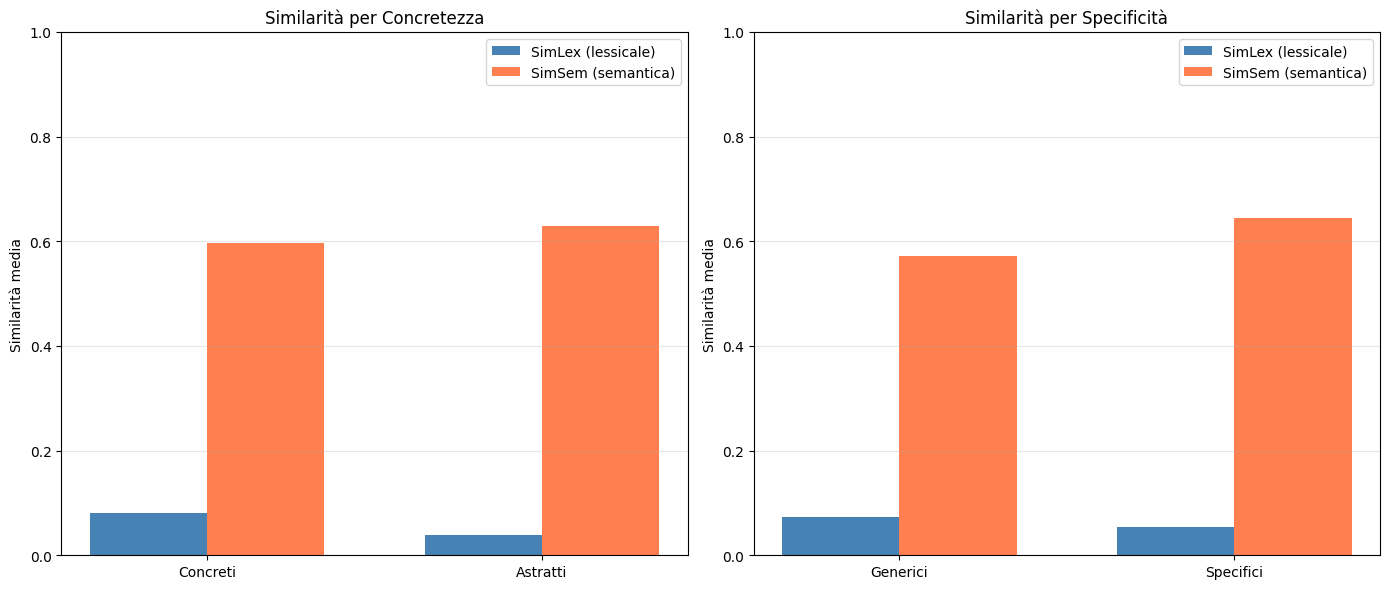

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Grafico Concretezza
categories_concr = ['Concreti', 'Astratti']
simlex_concr = [simlex_concrete, simlex_abstract]
simsem_concr = [simsem_concrete, simsem_abstract]

x = np.arange(len(categories_concr))
width = 0.35

axes[0].bar(x - width/2, simlex_concr, width, label='SimLex (lessicale)', color='steelblue')
axes[0].bar(x + width/2, simsem_concr, width, label='SimSem (semantica)', color='coral')
axes[0].set_ylabel('Similarità media')
axes[0].set_title('Similarità per Concretezza')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories_concr)
axes[0].legend()
axes[0].set_ylim(0, 1)
axes[0].grid(axis='y', alpha=0.3)

# Grafico Specificità
categories_spec = ['Generici', 'Specifici']
simlex_spec = [simlex_generic, simlex_specific]
simsem_spec = [simsem_generic, simsem_specific]

x = np.arange(len(categories_spec))

axes[1].bar(x - width/2, simlex_spec, width, label='SimLex (lessicale)', color='steelblue')
axes[1].bar(x + width/2, simsem_spec, width, label='SimSem (semantica)', color='coral')
axes[1].set_ylabel('Similarità media')
axes[1].set_title('Similarità per Specificità')
axes[1].set_xticks(x)
axes[1].set_xticklabels(categories_spec)
axes[1].legend()
axes[1].set_ylim(0, 1)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('fase4_similarity_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

#Funzioni di aggregazione

In [ ]:
def calc_avg_simlex(definitions):
    """Calcola SimLex medio tra tutte le coppie di definizioni (Jaccard su lemmi)"""
    scores = []
    for d1, d2 in itertools.combinations(definitions, 2):
        set1 = preprocess_with_lemma(d1)
        set2 = preprocess_with_lemma(d2)
        score = len(set1 & set2) / len(set1 | set2) if len(set1 | set2) > 0 else 0
        scores.append(score)
    return sum(scores) / len(scores) if scores else 0

def calc_avg_simsem(definitions):
    """Calcola SimSem medio tra tutte le coppie (cosine similarity su embeddings spaCy)"""
    scores = []
    for d1, d2 in itertools.combinations(definitions, 2):
        scores.append(nlp(d1).similarity(nlp(d2)))
    return sum(scores) / len(scores) if scores else 0

#4.3-4.4 Aggregazione per gruppi

In [ ]:
concrete_defs = term_dict['Pantalone'] + term_dict['Microscopio']
abstract_defs = term_dict['Pericolo'] + term_dict['Euristica']
generic_defs = term_dict['Pantalone'] + term_dict['Pericolo']
specific_defs = term_dict['Microscopio'] + term_dict['Euristica']

def calc_avg_simlex(definitions):
    """Calcola SimLex medio tra tutte le coppie di definizioni"""
    scores = []
    for d1, d2 in itertools.combinations(definitions, 2):
        set1 = preprocess_with_lemma(d1)
        set2 = preprocess_with_lemma(d2)
        score = len(set1 & set2) / len(set1 | set2) if len(set1 | set2) > 0 else 0
        scores.append(score)
    return sum(scores) / len(scores) if scores else 0

def calc_avg_simsem(definitions):
    """Calcola SimSem medio tra tutte le coppie di definizioni"""
    scores = []
    for d1, d2 in itertools.combinations(definitions, 2):
        scores.append(nlp(d1).similarity(nlp(d2)))
    return sum(scores) / len(scores) if scores else 0

# Calcoli per Concretezza
simlex_concrete = calc_avg_simlex(concrete_defs)
simlex_abstract = calc_avg_simlex(abstract_defs)
simsem_concrete = calc_avg_simsem(concrete_defs)
simsem_abstract = calc_avg_simsem(abstract_defs)

# Calcoli per Specificità
simlex_generic = calc_avg_simlex(generic_defs)
simlex_specific = calc_avg_simlex(specific_defs)
simsem_generic = calc_avg_simsem(generic_defs)
simsem_specific = calc_avg_simsem(specific_defs)

print("\n--- DIMENSIONE: CONCRETEZZA ---")
print(f"SimLex Concreti:  {simlex_concrete:.3f}")
print(f"SimLex Astratti:  {simlex_abstract:.3f}")
print(f"SimSem Concreti:  {simsem_concrete:.3f}")
print(f"SimSem Astratti:  {simsem_abstract:.3f}")

print("\n--- DIMENSIONE: SPECIFICITÀ ---")
print(f"SimLex Generici:  {simlex_generic:.3f}")
print(f"SimLex Specifici: {simlex_specific:.3f}")
print(f"SimSem Generici:  {simsem_generic:.3f}")
print(f"SimSem Specifici: {simsem_specific:.3f}")


FASE 4.3-4.4: AGGREGAZIONE PER CONCRETEZZA E SPECIFICITÀ

--- DIMENSIONE: CONCRETEZZA ---
SimLex Concreti:  0.081
SimLex Astratti:  0.039
SimSem Concreti:  0.596
SimSem Astratti:  0.630

--- DIMENSIONE: SPECIFICITÀ ---
SimLex Generici:  0.074
SimLex Specifici: 0.053
SimSem Generici:  0.572
SimSem Specifici: 0.645


#5. Visualizzazione e analisi


FASE 5: ANALISI E VISUALIZZAZIONE DEI RISULTATI

Tabella Riepilogativa per Termine:
    Termine   SimLex   SimSem               Tipo Concretezza Specificità
  Pantalone 0.171277 0.598184  Concreto-Generico    Concreto    Generico
Microscopio 0.150620 0.706491 Concreto-Specifico    Concreto   Specifico
   Pericolo 0.114913 0.684686  Astratto-Generico    Astratto    Generico
  Euristica 0.033389 0.632583 Astratto-Specifico    Astratto   Specifico


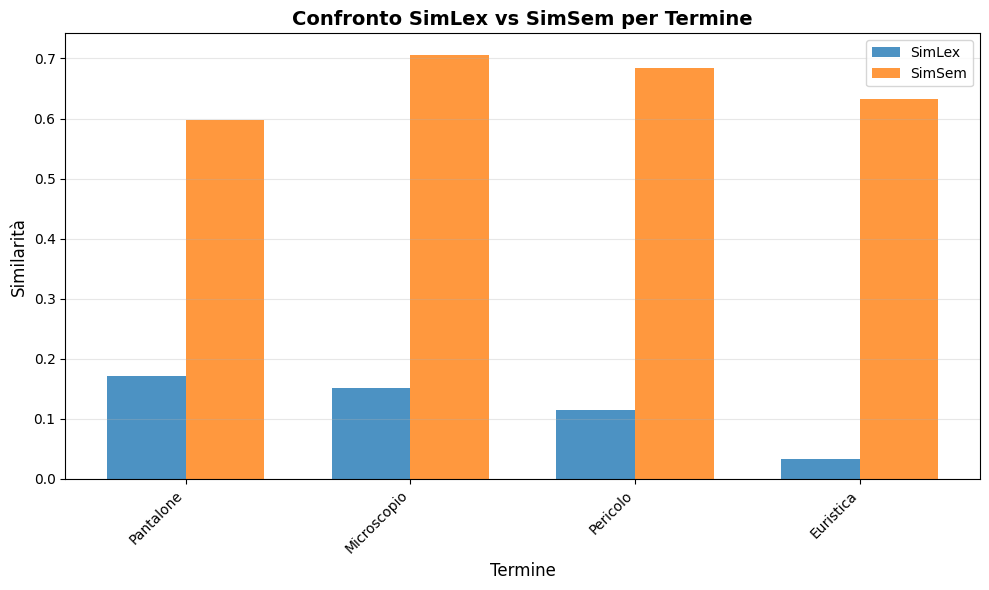

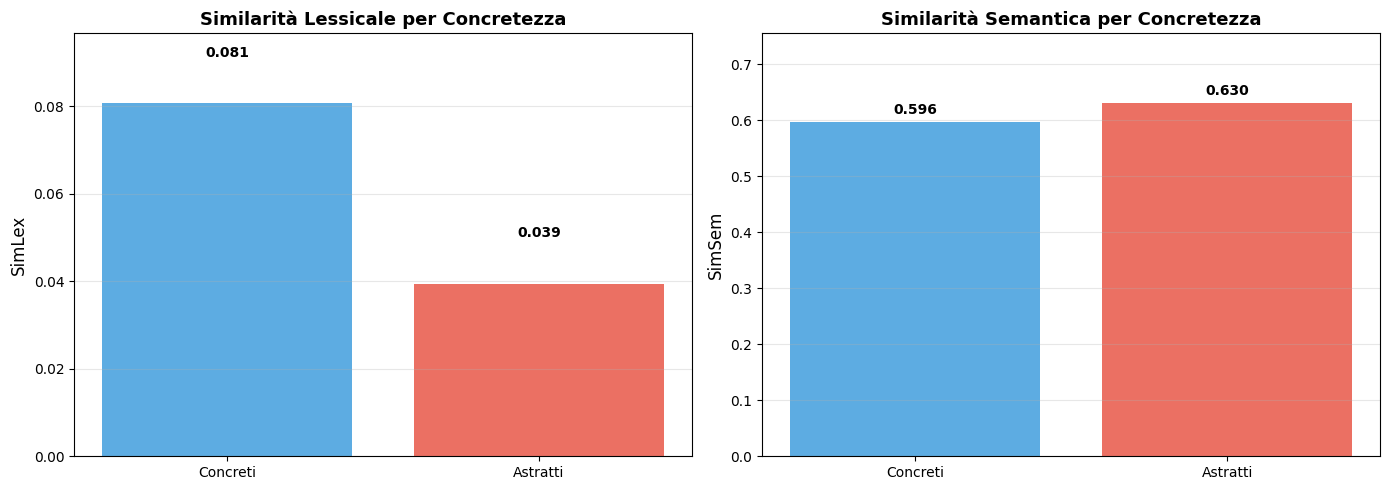

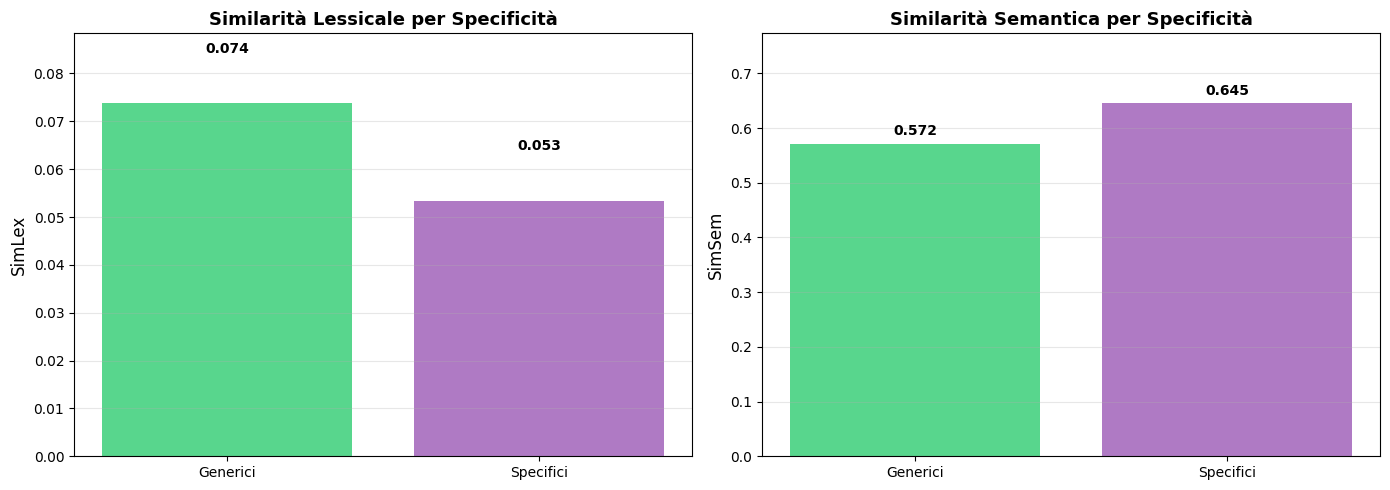

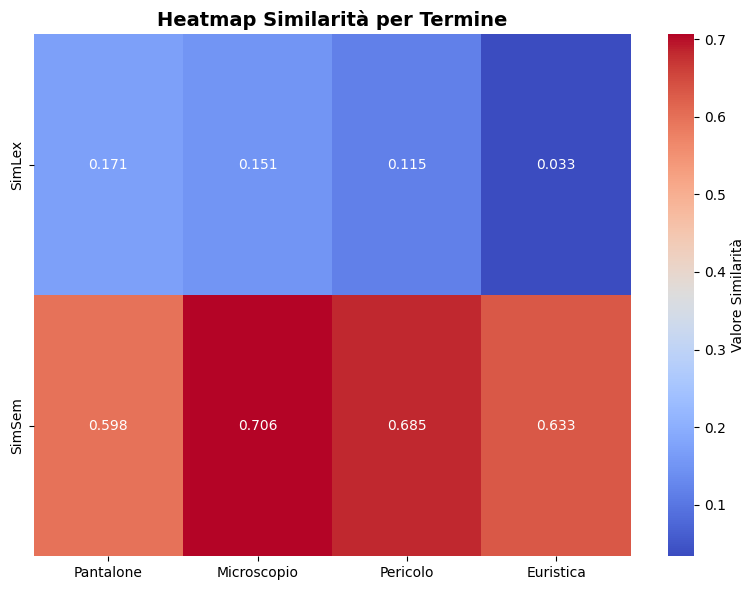

In [ ]:
# Preparazione dati per visualizzazioni
results_df = pd.DataFrame({
    'Termine': list(simlex_by_term.keys()),
    'SimLex': list(simlex_by_term.values()),
    'SimSem': list(simsem_by_term.values()),
    'Tipo': ['Concreto-Generico', 'Concreto-Specifico',
             'Astratto-Generico', 'Astratto-Specifico'],
    'Concretezza': ['Concreto', 'Concreto', 'Astratto', 'Astratto'],
    'Specificità': ['Generico', 'Specifico', 'Generico', 'Specifico']
})

print("\nTabella Riepilogativa per Termine:")
print(results_df.to_string(index=False))

# GRAFICO 1: Confronto SimLex e SimSem per termine
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

x = np.arange(len(results_df))
width = 0.35

ax.bar(x - width/2, results_df['SimLex'], width, label='SimLex', alpha=0.8)
ax.bar(x + width/2, results_df['SimSem'], width, label='SimSem', alpha=0.8)

ax.set_xlabel('Termine', fontsize=12)
ax.set_ylabel('Similarità', fontsize=12)
ax.set_title('Confronto SimLex vs SimSem per Termine', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(results_df['Termine'], rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# GRAFICO 2: Confronto per Concretezza
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

categories = ['Concreti', 'Astratti']
simlex_values = [simlex_concrete, simlex_abstract]
simsem_values = [simsem_concrete, simsem_abstract]

x_pos = np.arange(len(categories))

ax1.bar(x_pos, simlex_values, color=['#3498db', '#e74c3c'], alpha=0.8)
ax1.set_ylabel('SimLex', fontsize=12)
ax1.set_title('Similarità Lessicale per Concretezza', fontsize=13, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, max(simlex_values) * 1.2)
ax1.grid(axis='y', alpha=0.3)

for i, v in enumerate(simlex_values):
    ax1.text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

ax2.bar(x_pos, simsem_values, color=['#3498db', '#e74c3c'], alpha=0.8)
ax2.set_ylabel('SimSem', fontsize=12)
ax2.set_title('Similarità Semantica per Concretezza', fontsize=13, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(categories)
ax2.set_ylim(0, max(simsem_values) * 1.2)
ax2.grid(axis='y', alpha=0.3)

for i, v in enumerate(simsem_values):
    ax2.text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# GRAFICO 3: Confronto per Specificità
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

categories = ['Generici', 'Specifici']
simlex_values = [simlex_generic, simlex_specific]
simsem_values = [simsem_generic, simsem_specific]

x_pos = np.arange(len(categories))

ax1.bar(x_pos, simlex_values, color=['#2ecc71', '#9b59b6'], alpha=0.8)
ax1.set_ylabel('SimLex', fontsize=12)
ax1.set_title('Similarità Lessicale per Specificità', fontsize=13, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, max(simlex_values) * 1.2)
ax1.grid(axis='y', alpha=0.3)

for i, v in enumerate(simlex_values):
    ax1.text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

ax2.bar(x_pos, simsem_values, color=['#2ecc71', '#9b59b6'], alpha=0.8)
ax2.set_ylabel('SimSem', fontsize=12)
ax2.set_title('Similarità Semantica per Specificità', fontsize=13, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(categories)
ax2.set_ylim(0, max(simsem_values) * 1.2)
ax2.grid(axis='y', alpha=0.3)

for i, v in enumerate(simsem_values):
    ax2.text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# GRAFICO 4: Heatmap correlazioni
fig, ax = plt.subplots(figsize=(8, 6))

correlation_data = results_df[['SimLex', 'SimSem']].T
sns.heatmap(correlation_data, annot=True, fmt='.3f', cmap='coolwarm',
            xticklabels=results_df['Termine'], yticklabels=['SimLex', 'SimSem'],
            cbar_kws={'label': 'Valore Similarità'})

plt.title('Heatmap Similarità per Termine', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#Riflessioni

In [ ]:
print("\n1. DIFFERENZA TRA SIMLEX E SIMSEM:")
diff_by_term = {term: simsem_by_term[term] - simlex_by_term[term]
                for term in simlex_by_term}
for term, diff in diff_by_term.items():
    print(f"   {term:15s}: SimSem - SimLex = {diff:+.3f}")

print("\n2. CONFRONTO CONCRETEZZA:")
print(f"   Δ SimLex (Concreti - Astratti): {simlex_concrete - simlex_abstract:+.3f}")
print(f"   Δ SimSem (Concreti - Astratti): {simsem_concrete - simsem_abstract:+.3f}")

print("\n3. CONFRONTO SPECIFICITÀ:")
print(f"   Δ SimLex (Generici - Specifici): {simlex_generic - simlex_specific:+.3f}")
print(f"   Δ SimSem (Generici - Specifici): {simsem_generic - simsem_specific:+.3f}")

print("\n4. STATISTICHE DESCRITTIVE:")
print(f"   SimLex - Media: {np.mean(list(simlex_by_term.values())):.3f}, "
      f"Dev.Std: {np.std(list(simlex_by_term.values())):.3f}")
print(f"   SimSem - Media: {np.mean(list(simsem_by_term.values())):.3f}, "
      f"Dev.Std: {np.std(list(simsem_by_term.values())):.3f}")



RIFLESSIONI SUI RISULTATI

1. DIFFERENZA TRA SIMLEX E SIMSEM:
   Pantalone      : SimSem - SimLex = +0.427
   Microscopio    : SimSem - SimLex = +0.556
   Pericolo       : SimSem - SimLex = +0.570
   Euristica      : SimSem - SimLex = +0.599

2. CONFRONTO CONCRETEZZA:
   Δ SimLex (Concreti - Astratti): +0.041
   Δ SimSem (Concreti - Astratti): -0.033

3. CONFRONTO SPECIFICITÀ:
   Δ SimLex (Generici - Specifici): +0.020
   Δ SimSem (Generici - Specifici): -0.073

4. STATISTICHE DESCRITTIVE:
   SimLex - Media: 0.118, Dev.Std: 0.053
   SimSem - Media: 0.655, Dev.Std: 0.043

ANALISI COMPLETATA
